In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project
current_dir = Path.cwd()

PROJECT_ROOT = next(
    (
        path for path in [current_dir, *current_dir.parents]
        if (path / "data" / "raw" / "beijing_air_quality").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the AirSense project directory.")

# Locate the dataset
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "beijing_air_quality"

# Search recursively for the 12 station CSV files
csv_files = sorted(DATA_DIR.rglob("PRSA_Data_*.csv"))

print(f"Project root: {PROJECT_ROOT}")
print(f"Station files found: {len(csv_files)}")

if len(csv_files) != 12:
    raise ValueError(f"Expected 12 station files, but found {len(csv_files)}.")

# Load and combine the station datasets
dataframes = [pd.read_csv(file) for file in csv_files]

df = pd.concat(dataframes, ignore_index=True)

print(f"\nCombined dataset shape: {df.shape}")
print(f"Number of monitoring stations: {df['station'].nunique()}")

df.head()

Project root: C:\Users\HomePC\ML Zoomcamp 2026\Homework\Homework 7 Midterm Project
Station files found: 12

Combined dataset shape: (420768, 18)
Number of monitoring stations: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

Dataset shape: (420768, 18)

Columns:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    

In [3]:
# Count missing values per column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (df.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing_values, "missing_percentage": missing_percentage})
missing_summary = missing_summary.sort_values(by="missing_percentage", ascending=False)

missing_summary

,missing_count,missing_percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
PRES,393,0.09
RAIN,390,0.09


In [4]:
# Check for completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate timestamps within each station
print("Duplicate station timestamps:", df.duplicated(subset=["station", "year", "month", "day", "hour"]).sum())

Duplicate rows: 0
Duplicate station timestamps: 0


In [5]:
station_counts = df["station"].value_counts().sort_values()

station_counts

station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64

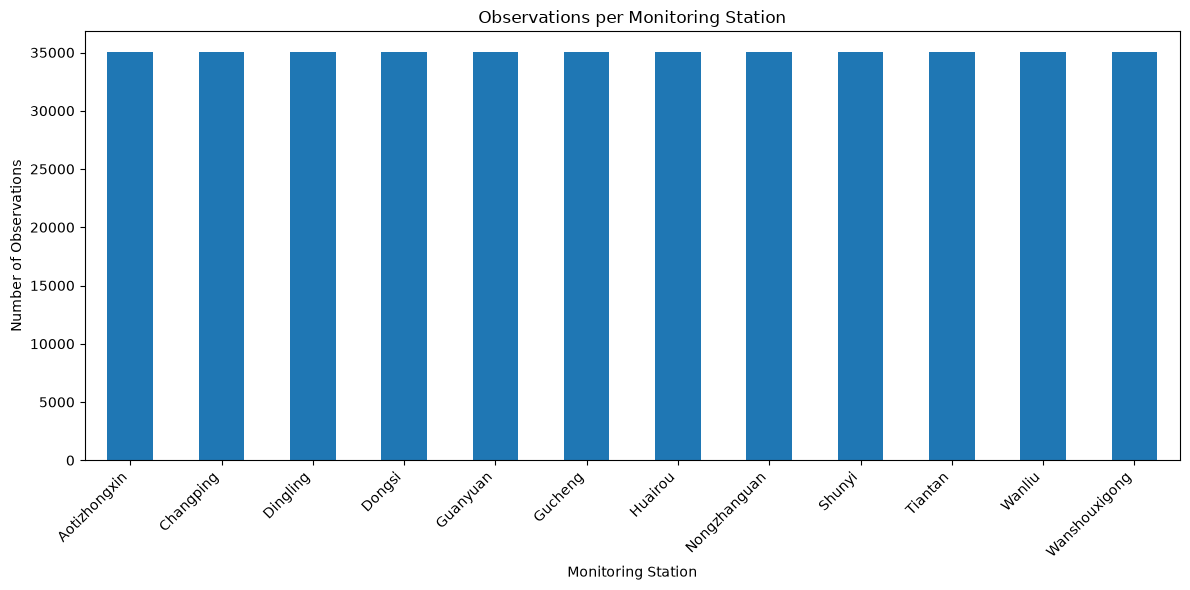

In [6]:
plt.figure(figsize=(12, 6))
station_counts.plot(kind="bar")
plt.title("Observations per Monitoring Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.50,10122.12,1.00,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.66,1.18,2013.00,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.52,3.45,1.00,4.00,7.0,10.00,12.0
day,420768.0,15.73,8.80,1.00,8.00,16.0,23.00,31.0
hour,420768.0,11.50,6.92,0.00,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.79,80.82,2.00,20.00,55.0,111.00,999.0
PM10,414319.0,104.60,91.77,2.00,36.00,82.0,145.00,999.0
SO2,411747.0,15.83,21.65,0.29,3.00,7.0,20.00,500.0
NO2,408652.0,50.64,35.13,1.03,23.00,43.0,71.00,290.0
CO,400067.0,1230.77,1160.18,100.00,500.00,900.0,1500.00,10000.0


In [8]:
# Create a datetime column from the individual time components
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

# Sort observations chronologically within each station
df = df.sort_values(
    ["station", "datetime"]
).reset_index(drop=True)

# Inspect the datetime column
print("Start:", df["datetime"].min())
print("End:", df["datetime"].max())
print("Missing datetime values:", df["datetime"].isna().sum())

df[["station", "datetime", "PM2.5"]].head()

Start: 2013-03-01 00:00:00
End: 2017-02-28 23:00:00
Missing datetime values: 0


,station,datetime,PM2.5
0,Aotizhongxin,2013-03-01 00:00:00,4.0
1,Aotizhongxin,2013-03-01 01:00:00,8.0
2,Aotizhongxin,2013-03-01 02:00:00,7.0
3,Aotizhongxin,2013-03-01 03:00:00,6.0
4,Aotizhongxin,2013-03-01 04:00:00,3.0


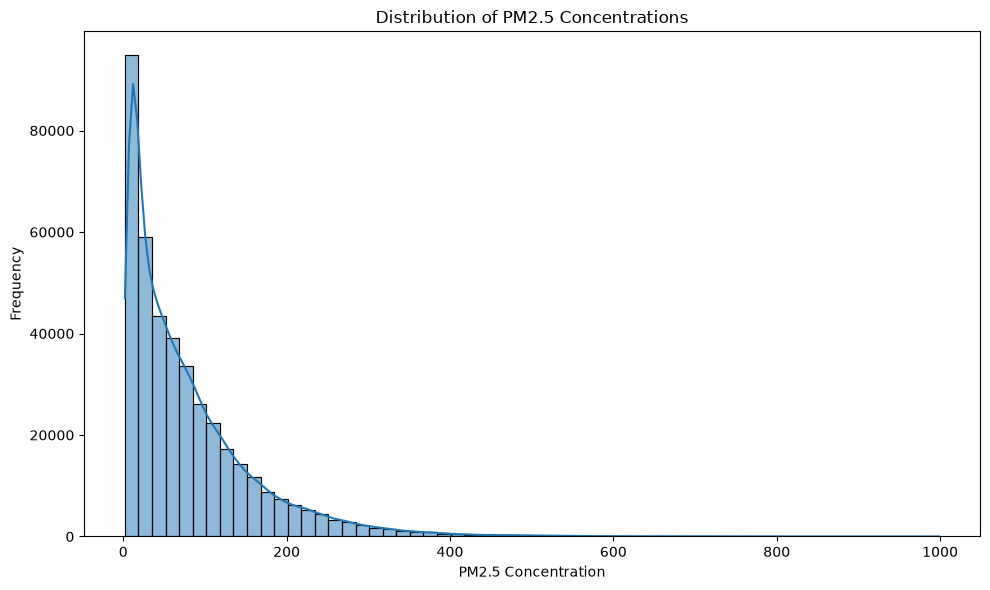

In [9]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="PM2.5", bins=60, kde=True)
plt.title("Distribution of PM2.5 Concentrations")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

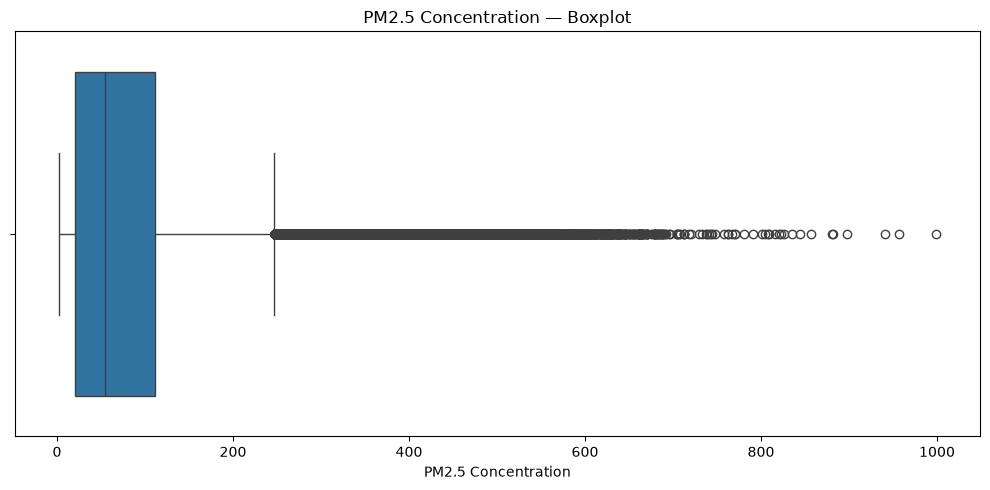

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="PM2.5")
plt.title("PM2.5 Concentration — Boxplot")
plt.xlabel("PM2.5 Concentration")
plt.tight_layout()
plt.show()

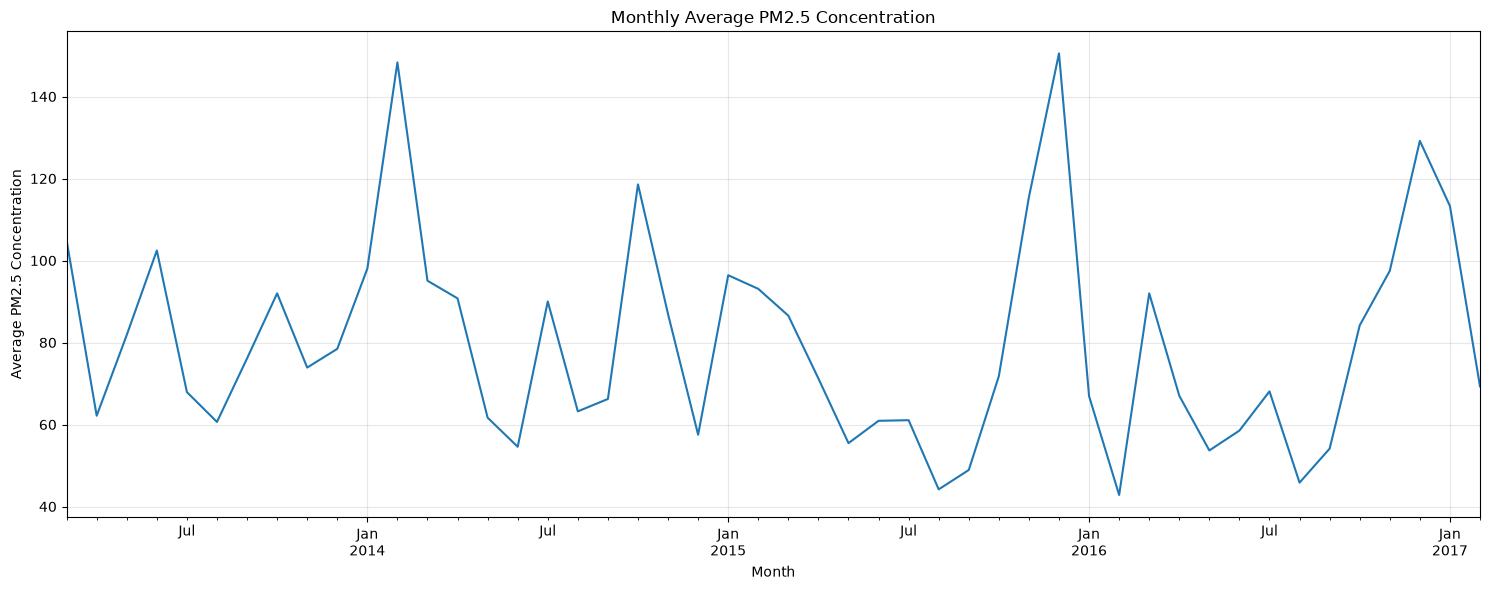

In [11]:
monthly_pm25 = (df.groupby(df["datetime"].dt.to_period("M"))["PM2.5"].mean())
plt.figure(figsize=(15, 6))
monthly_pm25.plot()
plt.title("Monthly Average PM2.5 Concentration")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 Concentration")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

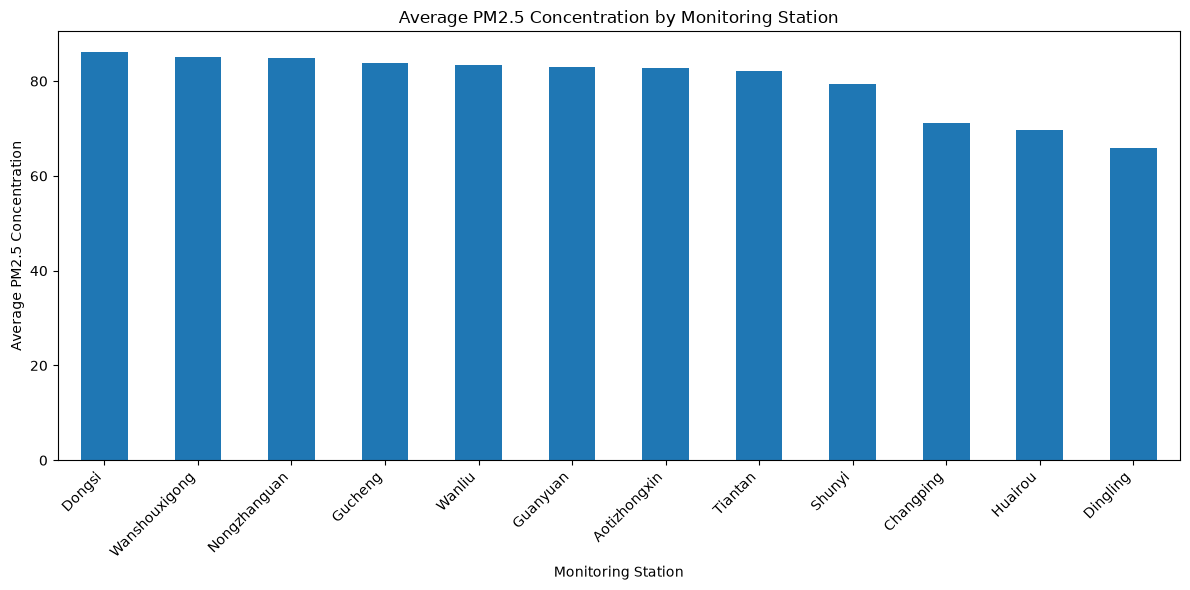

In [12]:
station_pm25 = (df.groupby("station")["PM2.5"].mean().sort_values(ascending=False))
plt.figure(figsize=(12, 6))
station_pm25.plot(kind="bar")
plt.title("Average PM2.5 Concentration by Monitoring Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

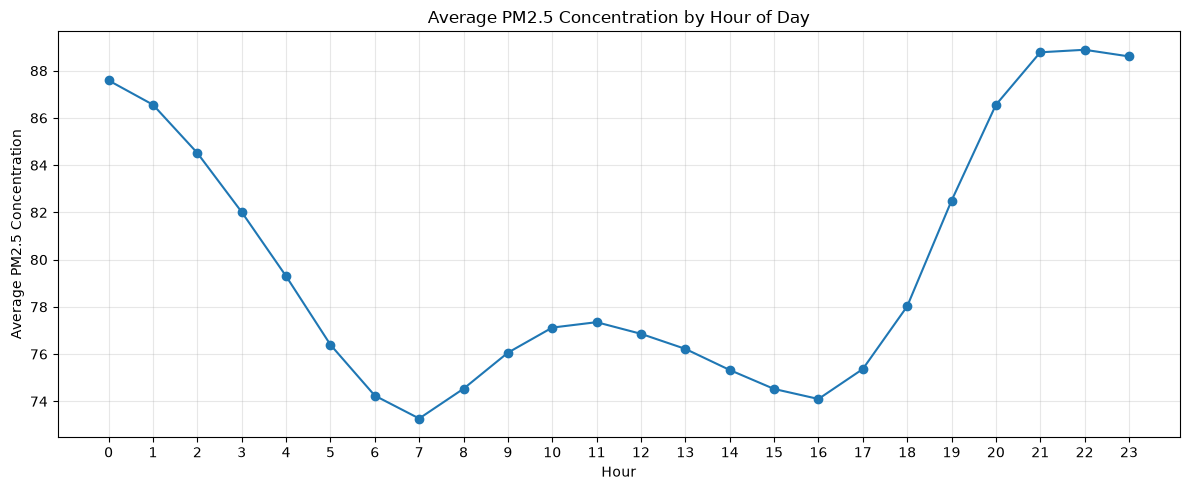

In [13]:
hourly_pm25 = (df.groupby("hour")["PM2.5"].mean())
plt.figure(figsize=(12, 5))
hourly_pm25.plot(marker="o")
plt.title("Average PM2.5 Concentration by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

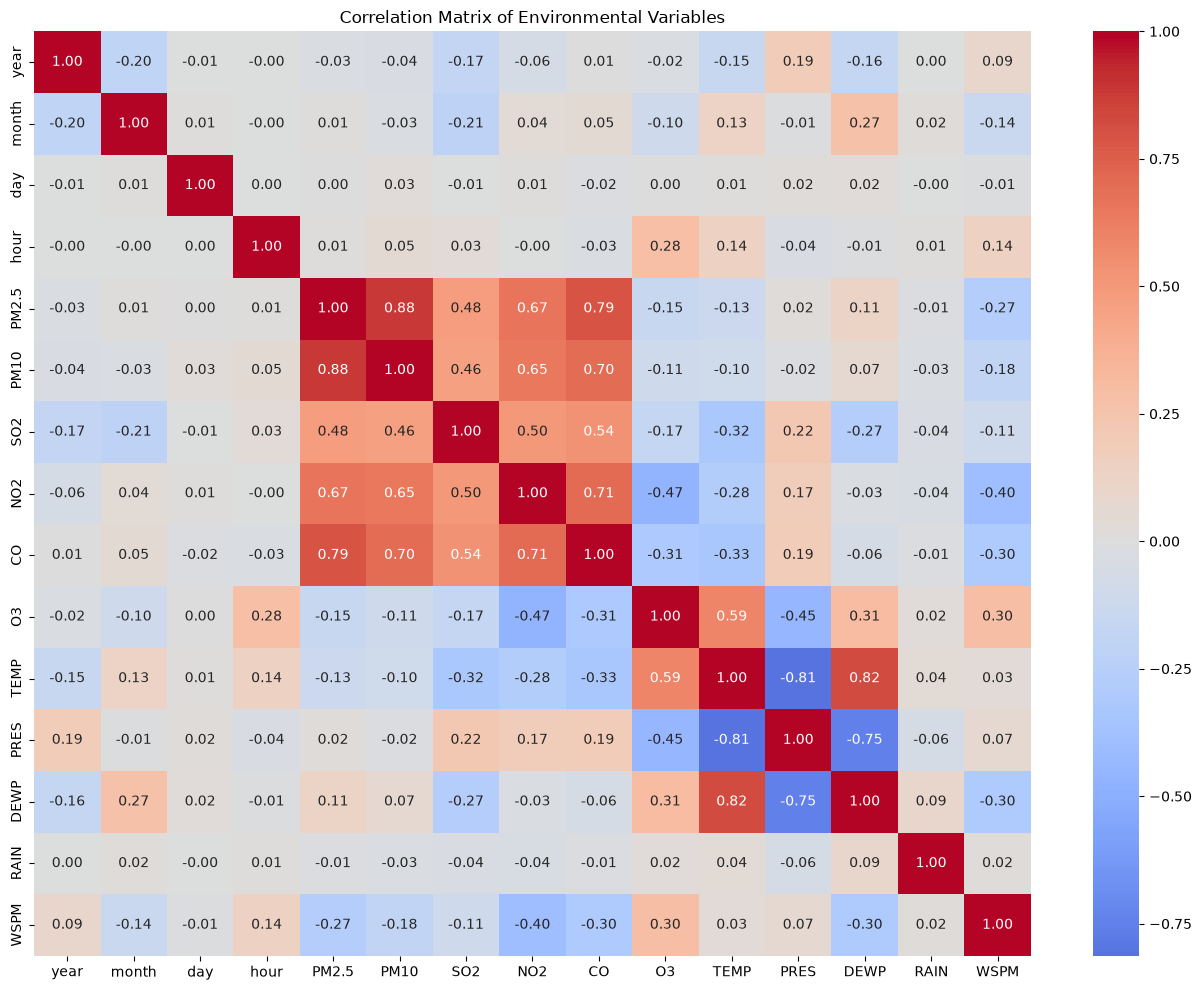

In [14]:
correlation = df.select_dtypes(include="number").drop(columns=["No"]).corr()
plt.figure(figsize=(13, 10))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",center=0)
plt.title("Correlation Matrix of Environmental Variables")
plt.tight_layout()
plt.show()

In [15]:
# Calculate the time difference between consecutive observations
df["time_difference"] = (df.groupby("station")["datetime"].diff())

# Count gaps that are not exactly one hour
time_gaps = df[(df["time_difference"].notna()) & (df["time_difference"] != pd.Timedelta(hours=1))]
print("Total time gaps:", len(time_gaps))

print("\nTime gap examples:")
time_gaps[["station", "datetime", "time_difference"]].head(10)

Total time gaps: 0

Time gap examples:


,station,datetime,time_difference


In [16]:
# Create the next-hour PM2.5 target within each station
df["target_pm25"] = (df.groupby("station")["PM2.5"].shift(-1))

# Check target creation
print("Total observations:", len(df))
print("Missing future PM2.5 targets:", df["target_pm25"].isna().sum())

df[["station", "datetime", "PM2.5", "target_pm25"]].head(10)

Total observations: 420768
Missing future PM2.5 targets: 8751


,station,datetime,PM2.5,target_pm25
0,Aotizhongxin,2013-03-01 00:00:00,4.0,8.0
1,Aotizhongxin,2013-03-01 01:00:00,8.0,7.0
2,Aotizhongxin,2013-03-01 02:00:00,7.0,6.0
3,Aotizhongxin,2013-03-01 03:00:00,6.0,3.0
4,Aotizhongxin,2013-03-01 04:00:00,3.0,5.0
5,Aotizhongxin,2013-03-01 05:00:00,5.0,3.0
6,Aotizhongxin,2013-03-01 06:00:00,3.0,3.0
7,Aotizhongxin,2013-03-01 07:00:00,3.0,3.0
8,Aotizhongxin,2013-03-01 08:00:00,3.0,3.0
9,Aotizhongxin,2013-03-01 09:00:00,3.0,3.0


In [17]:
# Inspect a few observations from one station
df.loc[df["station"] == "Aotizhongxin", ["datetime", "PM2.5", "target_pm25"]].head(10)

,datetime,PM2.5,target_pm25
0,2013-03-01 00:00:00,4.0,8.0
1,2013-03-01 01:00:00,8.0,7.0
2,2013-03-01 02:00:00,7.0,6.0
3,2013-03-01 03:00:00,6.0,3.0
4,2013-03-01 04:00:00,3.0,5.0
5,2013-03-01 05:00:00,5.0,3.0
6,2013-03-01 06:00:00,3.0,3.0
7,2013-03-01 07:00:00,3.0,3.0
8,2013-03-01 08:00:00,3.0,3.0
9,2013-03-01 09:00:00,3.0,3.0


In [18]:
# Count the final observation for each station
last_observations = (df.groupby("station")["datetime"].idxmax())
print("Final observation rows:", len(last_observations))

# Count missing targets on the final observation of each station
print("Missing targets at station boundaries:", df.loc[last_observations, "target_pm25"].isna().sum())

# Count missing targets elsewhere
print("Missing targets within station timelines:", df["target_pm25"].isna().sum() - df.loc[last_observations, "target_pm25"].isna().sum())

Final observation rows: 12
Missing targets at station boundaries: 12
Missing targets within station timelines: 8739


In [19]:
# Create historical PM2.5 lag features
for lag in [1, 3, 6, 24]:
    df[f"pm25_lag_{lag}"] = (df.groupby("station")["PM2.5"].shift(lag))

df[["station", "datetime", "PM2.5", "pm25_lag_1", "pm25_lag_3", "pm25_lag_6", "pm25_lag_24", "target_pm25"]].head(30)

,station,datetime,PM2.5,pm25_lag_1,pm25_lag_3,pm25_lag_6,pm25_lag_24,target_pm25
0,Aotizhongxin,2013-03-01 00:00:00,4.0,NaN,NaN,NaN,NaN,8.0
1,Aotizhongxin,2013-03-01 01:00:00,8.0,4.0,NaN,NaN,NaN,7.0
2,Aotizhongxin,2013-03-01 02:00:00,7.0,8.0,NaN,NaN,NaN,6.0
3,Aotizhongxin,2013-03-01 03:00:00,6.0,7.0,4.0,NaN,NaN,3.0
4,Aotizhongxin,2013-03-01 04:00:00,3.0,6.0,8.0,NaN,NaN,5.0
5,Aotizhongxin,2013-03-01 05:00:00,5.0,3.0,7.0,NaN,NaN,3.0
6,Aotizhongxin,2013-03-01 06:00:00,3.0,5.0,6.0,4.0,NaN,3.0
7,Aotizhongxin,2013-03-01 07:00:00,3.0,3.0,3.0,8.0,NaN,3.0
8,Aotizhongxin,2013-03-01 08:00:00,3.0,3.0,5.0,7.0,NaN,3.0
9,Aotizhongxin,2013-03-01 09:00:00,3.0,3.0,3.0,6.0,NaN,3.0


In [20]:
# Create historical rolling averages
for window in [3, 6, 24]:
    df[f"pm25_rolling_mean_{window}"] = (df.groupby("station")["PM2.5"].transform(lambda x: x.shift(1).rolling(window=window, min_periods=window).mean()))

In [21]:
df["hour"] = df["datetime"].dt.hour
df["day_of_week"] = df["datetime"].dt.day_of_week
df["month"] = df["datetime"].dt.month
df["day_of_year"] = df["datetime"].dt.day_of_year

In [22]:
feature_columns = ["PM2.5", "pm25_lag_1", "pm25_lag_3", "pm25_lag_6", "pm25_lag_24", "pm25_rolling_mean_3", "pm25_rolling_mean_6", "pm25_rolling_mean_24", "hour", "day_of_week", "month", "day_of_year", "target_pm25"]

df[feature_columns].head(30)

,PM2.5,pm25_lag_1,pm25_lag_3,pm25_lag_6,pm25_lag_24,pm25_rolling_mean_3,pm25_rolling_mean_6,pm25_rolling_mean_24,hour,day_of_week,month,day_of_year,target_pm25
0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,4,3,60,8.0
1,8.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,1,4,3,60,7.0
2,7.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,2,4,3,60,6.0
3,6.0,7.0,4.0,NaN,NaN,6.333333,NaN,NaN,3,4,3,60,3.0
4,3.0,6.0,8.0,NaN,NaN,7.000000,NaN,NaN,4,4,3,60,5.0
5,5.0,3.0,7.0,NaN,NaN,5.333333,NaN,NaN,5,4,3,60,3.0
6,3.0,5.0,6.0,4.0,NaN,4.666667,5.500000,NaN,6,4,3,60,3.0
7,3.0,3.0,3.0,8.0,NaN,3.666667,5.333333,NaN,7,4,3,60,3.0
8,3.0,3.0,5.0,7.0,NaN,3.666667,4.500000,NaN,8,4,3,60,3.0
9,3.0,3.0,3.0,6.0,NaN,3.000000,3.833333,NaN,9,4,3,60,3.0


In [23]:
weather_features = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

for column in weather_features:
    df[f"{column.lower()}_current"] = df[column]

In [24]:
engineered_features = ["PM2.5","pm25_lag_1","pm25_lag_3","pm25_lag_6","pm25_lag_24","pm25_rolling_mean_3","pm25_rolling_mean_6","pm25_rolling_mean_24","TEMP","PRES","DEWP","RAIN","WSPM","wd","target_pm25"]

feature_missing = pd.DataFrame({"missing_count": df[engineered_features].isna().sum(),
    "missing_percentage": (df[engineered_features].isna().mean() * 100).round(2)
})

feature_missing.sort_values("missing_percentage",ascending=False)

,missing_count,missing_percentage
pm25_rolling_mean_24,57975,13.78
pm25_rolling_mean_6,21395,5.08
pm25_rolling_mean_3,14261,3.39
pm25_lag_24,9016,2.14
pm25_lag_3,8775,2.09
pm25_lag_6,8811,2.09
pm25_lag_1,8751,2.08
PM2.5,8739,2.08
target_pm25,8751,2.08
wd,1822,0.43


In [25]:
model_df = df.copy()

# Remove observations without a known next-hour PM2.5 target
model_df = model_df.dropna(subset=["target_pm25"]).copy()

print("Original observations:", len(df))
print("Observations with valid targets:", len(model_df))
print("Remaining missing targets:", model_df["target_pm25"].isna().sum())

Original observations: 420768
Observations with valid targets: 412017
Remaining missing targets: 0


In [26]:
# Get all unique timestamps in chronological order
unique_dates = sorted(model_df["datetime"].unique())

# Calculate split positions
train_idx = int(len(unique_dates) * 0.70)
val_idx = int(len(unique_dates) * 0.85)

# Determine cutoff timestamps
train_end = unique_dates[train_idx - 1]
val_end = unique_dates[val_idx - 1]

print("Training ends:", train_end)
print("Validation ends:", val_end)
print("Test ends:", unique_dates[-1])

Training ends: 2015-12-18 04:00:00
Validation ends: 2016-07-24 04:00:00
Test ends: 2017-02-28 22:00:00


In [27]:
# Training: earliest 70%
train_df = model_df[model_df["datetime"] <= train_end].copy()

# Validation: next 15%
val_df = model_df[(model_df["datetime"] > train_end) & (model_df["datetime"] <= val_end)].copy()

# Test: final 15%
test_df = model_df[model_df["datetime"] > val_end].copy()

In [28]:
splits = {"Train": train_df, "Validation": val_df, "Test": test_df}

for name, split in splits.items():
    print(f"\n{name}")
    print("Rows:", len(split))
    print("Start:", split["datetime"].min())
    print("End:", split["datetime"].max())
    print("Stations:", split["station"].nunique())


Train
Rows: 288246
Start: 2013-03-01 00:00:00
End: 2015-12-18 04:00:00
Stations: 12

Validation
Rows: 61785
Start: 2015-12-18 05:00:00
End: 2016-07-24 04:00:00
Stations: 12

Test
Rows: 61986
Start: 2016-07-24 05:00:00
End: 2017-02-28 22:00:00
Stations: 12


In [29]:
# Timestamp corresponding to the target PM2.5 measurement
model_df["target_datetime"] = (model_df["datetime"] + pd.Timedelta(hours=1))

In [30]:
# Use target timestamps rather than feature timestamps
unique_target_dates = sorted(model_df["target_datetime"].unique())

train_idx = int(len(unique_target_dates) * 0.70)
val_idx = int(len(unique_target_dates) * 0.85)

train_end = unique_target_dates[train_idx - 1]
val_end = unique_target_dates[val_idx - 1]

print("Training target period ends:", train_end)
print("Validation target period ends:", val_end)
print("Test target period ends:", unique_target_dates[-1])

Training target period ends: 2015-12-18 05:00:00
Validation target period ends: 2016-07-24 05:00:00
Test target period ends: 2017-02-28 23:00:00


In [31]:
train_df = model_df[model_df["target_datetime"] <= train_end].copy()

val_df = model_df[(model_df["target_datetime"] > train_end) & (model_df["target_datetime"] <= val_end)].copy()

test_df = model_df[model_df["target_datetime"] > val_end].copy()

In [32]:
splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, split in splits.items():
    print(f"\n{name}")
    print("Rows:", len(split))
    print("Feature period:", split["datetime"].min(), "to", split["datetime"].max())
    print("Target period:", split["target_datetime"].min(), "to", split["target_datetime"].max())
    print("Stations:", split["station"].nunique())


Train
Rows: 288246
Feature period: 2013-03-01 00:00:00 to 2015-12-18 04:00:00
Target period: 2013-03-01 01:00:00 to 2015-12-18 05:00:00
Stations: 12

Validation
Rows: 61785
Feature period: 2015-12-18 05:00:00 to 2016-07-24 04:00:00
Target period: 2015-12-18 06:00:00 to 2016-07-24 05:00:00
Stations: 12

Test
Rows: 61986
Feature period: 2016-07-24 05:00:00 to 2017-02-28 22:00:00
Target period: 2016-07-24 06:00:00 to 2017-02-28 23:00:00
Stations: 12


In [33]:
# Model A: Historical and temporal features
numeric_features_A = ["PM2.5","pm25_lag_1","pm25_lag_3","pm25_lag_6","pm25_lag_24","pm25_rolling_mean_3","pm25_rolling_mean_6","pm25_rolling_mean_24","hour","day_of_week","month","day_of_year"]
categorical_features_A = ["station"]

# Model B: Add weather information
numeric_features_B = numeric_features_A + ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
categorical_features_B = categorical_features_A + ["wd"]

print("Model A numeric features:", len(numeric_features_A))
print("Model A categorical features:", len(categorical_features_A))
print("\nModel B numeric features:", len(numeric_features_B))
print("Model B categorical features:", len(categorical_features_B))

Model A numeric features: 12
Model A categorical features: 1

Model B numeric features: 17
Model B categorical features: 2


In [34]:
for name, features in {
    "Model A": numeric_features_A + categorical_features_A,
    "Model B": numeric_features_B + categorical_features_B
}.items():

    missing_columns = [column for column in features if column not in model_df.columns]

    print(f"\n{name}")
    print("Total features:", len(features))
    print("Missing columns:", missing_columns)


Model A
Total features: 13
Missing columns: []

Model B
Total features: 19
Missing columns: []


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


def create_preprocessor(numeric_features, categorical_features):

    numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])

    categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])

    preprocessor = ColumnTransformer(transformers=[("numeric", numeric_transformer, numeric_features), ("categorical", categorical_transformer, categorical_features)])

    return preprocessor


preprocessor_A = create_preprocessor(numeric_features_A, categorical_features_A)
preprocessor_B = create_preprocessor(numeric_features_B, categorical_features_B)
print("Model A and Model B preprocessing pipelines created.")

Model A and Model B preprocessing pipelines created.


In [36]:
target = "target_pm25"

features_A = numeric_features_A + categorical_features_A
features_B = numeric_features_B + categorical_features_B

X_train_A = train_df[features_A]
X_val_A = val_df[features_A]
X_test_A = test_df[features_A]

X_train_B = train_df[features_B]
X_val_B = val_df[features_B]
X_test_B = test_df[features_B]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

print("Training:", X_train_A.shape, y_train.shape)
print("Validation:", X_val_A.shape, y_val.shape)
print("Testing:", X_test_A.shape, y_test.shape)

Training: (288246, 13) (288246,)
Validation: (61785, 13) (61785,)
Testing: (61986, 13) (61986,)


In [37]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_A, y_train)
baseline_predictions = baseline.predict(X_val_A)

baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_rmse = mean_squared_error(y_val, baseline_predictions) ** 0.5
baseline_r2 = r2_score(y_val, baseline_predictions)

print("Baseline Validation Results")
print("---------------------------")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))
print("R²:", round(baseline_r2, 3))

Baseline Validation Results
---------------------------
MAE: 58.288
RMSE: 82.247
R²: -0.01


In [38]:
from sklearn.preprocessing import StandardScaler

def create_preprocessor(numeric_features, categorical_features):

    numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

    categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])

    preprocessor = ColumnTransformer(
        transformers=[("numeric", numeric_transformer, numeric_features),("categorical", categorical_transformer, categorical_features)])

    return preprocessor


preprocessor_A = create_preprocessor(numeric_features_A, categorical_features_A)
preprocessor_B = create_preprocessor(numeric_features_B, categorical_features_B)
print("Updated preprocessing pipelines created.")

Updated preprocessing pipelines created.


In [39]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models_A = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=20, min_samples_leaf=2, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2, n_jobs=-1, random_state=42)
}

In [40]:
results_A = []
trained_models_A = {}

for name, model in models_A.items():

    pipeline = Pipeline(steps=[("preprocessor", preprocessor_A), ("model", model)])

    print(f"Training {name}...")

    pipeline.fit(X_train_A, y_train)

    predictions = pipeline.predict(X_val_A)

    mae = mean_absolute_error(y_val, predictions)
    rmse = mean_squared_error(y_val, predictions) ** 0.5
    r2 = r2_score(y_val, predictions)

    results_A.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models_A[name] = pipeline

    print(f"MAE: {mae:.3f} | " f"RMSE: {rmse:.3f} | " f"R²: {r2:.3f}")

print("\nModel A training complete.")

Training Linear Regression...
MAE: 10.635 | RMSE: 21.364 | R²: 0.932
Training Ridge Regression...
MAE: 10.635 | RMSE: 21.364 | R²: 0.932
Training Decision Tree...
MAE: 12.812 | RMSE: 26.089 | R²: 0.898
Training Random Forest...
MAE: 10.410 | RMSE: 20.782 | R²: 0.935

Model A training complete.


In [41]:
results_A_df = pd.DataFrame(results_A)
results_A_df = results_A_df.sort_values(by="RMSE", ascending=True).reset_index(drop=True)
results_A_df.round(3)

,Model,MAE,RMSE,R2
0,Random Forest,10.410,20.782,0.935
1,Linear Regression,10.635,21.364,0.932
2,Ridge Regression,10.635,21.364,0.932
3,Decision Tree,12.812,26.089,0.898


In [42]:
generalisation_A = []

for name, pipeline in trained_models_A.items():

    train_predictions = pipeline.predict(X_train_A)
    val_predictions = pipeline.predict(X_val_A)

    generalisation_A.append({
        "Model": name,
        "Train RMSE": mean_squared_error(
            y_train, train_predictions
        ) ** 0.5,
        "Validation RMSE": mean_squared_error(
            y_val, val_predictions
        ) ** 0.5,
        "Train MAE": mean_absolute_error(
            y_train, train_predictions
        ),
        "Validation MAE": mean_absolute_error(
            y_val, val_predictions
        )
    })

generalisation_A_df = pd.DataFrame(generalisation_A)
generalisation_A_df.round(3)

,Model,Train RMSE,Validation RMSE,Train MAE,Validation MAE
0,Linear Regression,20.778,21.364,10.936,10.635
1,Ridge Regression,20.778,21.364,10.936,10.635
2,Decision Tree,12.596,26.089,7.379,12.812
3,Random Forest,12.382,20.782,7.285,10.410


In [43]:
models_B = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=20, min_samples_leaf=2, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2, n_jobs=-1, random_state=42)
}

results_B = []
trained_models_B = {}

for name, model in models_B.items():

    pipeline = Pipeline(steps=[("preprocessor", preprocessor_B), ("model", model)])

    print(f"Training Model B: {name}...")

    pipeline.fit(X_train_B, y_train)

    predictions = pipeline.predict(X_val_B)

    mae = mean_absolute_error(y_val, predictions)
    rmse = mean_squared_error(y_val, predictions) ** 0.5
    r2 = r2_score(y_val, predictions)

    results_B.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models_B[name] = pipeline

    print(f"MAE: {mae:.3f} | " f"RMSE: {rmse:.3f} | " f"R²: {r2:.3f}")

results_B_df = pd.DataFrame(results_B)

results_B_df = results_B_df.sort_values(by="RMSE", ascending=True).reset_index(drop=True)
results_B_df.round(3)

Training Model B: Linear Regression...
MAE: 10.666 | RMSE: 21.169 | R²: 0.933
Training Model B: Ridge Regression...
MAE: 10.666 | RMSE: 21.169 | R²: 0.933
Training Model B: Decision Tree...
MAE: 12.290 | RMSE: 24.654 | R²: 0.909
Training Model B: Random Forest...
MAE: 10.010 | RMSE: 20.173 | R²: 0.939


,Model,MAE,RMSE,R2
0,Random Forest,10.010,20.173,0.939
1,Linear Regression,10.666,21.169,0.933
2,Ridge Regression,10.666,21.169,0.933
3,Decision Tree,12.290,24.654,0.909


In [44]:
comparison_df = pd.concat([results_A_df.assign(Feature_Set="Model A"), results_B_df.assign(Feature_Set="Model B")], ignore_index=True)
comparison_df = comparison_df.sort_values(by="RMSE", ascending=True ).reset_index(drop=True)
comparison_df[["Feature_Set", "Model", "MAE", "RMSE", "R2"]].round(3)

,Feature_Set,Model,MAE,RMSE,R2
0,Model B,Random Forest,10.010,20.173,0.939
1,Model A,Random Forest,10.410,20.782,0.935
2,Model B,Linear Regression,10.666,21.169,0.933
3,Model B,Ridge Regression,10.666,21.169,0.933
4,Model A,Linear Regression,10.635,21.364,0.932
5,Model A,Ridge Regression,10.635,21.364,0.932
6,Model B,Decision Tree,12.290,24.654,0.909
7,Model A,Decision Tree,12.812,26.089,0.898


In [45]:
generalisation_results = []

for feature_set, models, X_train, X_val in [("Model A", trained_models_A, X_train_A, X_val_A), ("Model B", trained_models_B, X_train_B, X_val_B)]:

    for name, pipeline in models.items():

        train_predictions = pipeline.predict(X_train)
        val_predictions = pipeline.predict(X_val)
        train_rmse = mean_squared_error(y_train, train_predictions) ** 0.5
        val_rmse = mean_squared_error(y_val, val_predictions) ** 0.5
        generalisation_results.append({
            "Feature Set": feature_set,
            "Model": name,
            "Train RMSE": train_rmse,
            "Validation RMSE": val_rmse,
            "RMSE Gap": val_rmse - train_rmse
        })

generalisation_df = pd.DataFrame(generalisation_results)
generalisation_df = generalisation_df.sort_values(by="Validation RMSE").reset_index(drop=True)
generalisation_df.round(3)

,Feature Set,Model,Train RMSE,Validation RMSE,RMSE Gap
0,Model B,Random Forest,12.197,20.173,7.976
1,Model A,Random Forest,12.382,20.782,8.400
2,Model B,Linear Regression,20.464,21.169,0.705
3,Model B,Ridge Regression,20.464,21.169,0.705
4,Model A,Linear Regression,20.778,21.364,0.586
5,Model A,Ridge Regression,20.778,21.364,0.586
6,Model B,Decision Tree,12.500,24.654,12.155
7,Model A,Decision Tree,12.596,26.089,13.493


In [46]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

# Sort by target timestamp
train_df_cv = train_df.sort_values("target_datetime").reset_index(drop=True)

# Get unique target timestamps
unique_cv_dates = np.sort(train_df_cv["target_datetime"].unique())

# Three expanding-window chronological folds
tscv = TimeSeriesSplit(n_splits=3)

cv_splits = []

for fold, (train_time_idx, val_time_idx) in enumerate(tscv.split(unique_cv_dates), start=1):

    fold_train_dates = unique_cv_dates[train_time_idx]
    fold_val_dates = unique_cv_dates[val_time_idx]

    fold_train_idx = np.flatnonzero(train_df_cv["target_datetime"].isin(fold_train_dates))
    fold_val_idx = np.flatnonzero(train_df_cv["target_datetime"].isin(fold_val_dates))

    cv_splits.append((fold_train_idx, fold_val_idx))

    print(f"\nFold {fold}")
    print("Training period:", train_df_cv.iloc[fold_train_idx]["target_datetime"].min(), "to", train_df_cv.iloc[fold_train_idx]["target_datetime"].max())
    print("Validation period:", train_df_cv.iloc[fold_val_idx]["target_datetime"].min(), "to", train_df_cv.iloc[fold_val_idx]["target_datetime"].max())
    print("Training rows:", len(fold_train_idx))
    print("Validation rows:", len(fold_val_idx))


Fold 1
Training period: 2013-03-01 01:00:00 to 2013-11-11 04:00:00
Validation period: 2013-11-11 05:00:00 to 2014-07-25 00:00:00
Training rows: 72314
Validation rows: 72201

Fold 2
Training period: 2013-03-01 01:00:00 to 2014-07-25 00:00:00
Validation period: 2014-07-25 01:00:00 to 2015-04-06 14:00:00
Training rows: 144515
Validation rows: 71847

Fold 3
Training period: 2013-03-01 01:00:00 to 2015-04-06 14:00:00
Validation period: 2015-04-06 15:00:00 to 2015-12-18 05:00:00
Training rows: 216362
Validation rows: 71884


In [47]:
X_train_B_cv = train_df_cv[features_B]
y_train_cv = train_df_cv[target]

print("Tuning dataset:", X_train_B_cv.shape)

Tuning dataset: (288246, 19)


In [48]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

rf_pipeline = Pipeline(steps=[("preprocessor", preprocessor_B), ("model", RandomForestRegressor( random_state=42, n_jobs=-1))])

param_distributions = {
    "model__n_estimators": [50, 100, 150],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": [0.7, 1.0]
}

In [49]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="neg_root_mean_squared_error",
    cv=cv_splits,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

random_search.fit(X_train_B_cv, y_train_cv)

print("\nBest parameters:")
print(random_search.best_params_)

print("\nBest cross-validation RMSE:")
print(-random_search.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best parameters:
{'model__n_estimators': 150, 'model__min_samples_leaf': 10, 'model__max_features': 0.7, 'model__max_depth': None}

Best cross-validation RMSE:
20.494694251343166


In [50]:
# Retrieve the best model from RandomizedSearchCV
best_rf = random_search.best_estimator_

# Predictions on training and validation data
tuned_train_predictions = best_rf.predict(X_train_B)
tuned_val_predictions = best_rf.predict(X_val_B)

# Calculate metrics
tuned_results = {
    "Train MAE": mean_absolute_error(
        y_train, tuned_train_predictions
    ),
    "Train RMSE": mean_squared_error(
        y_train, tuned_train_predictions
    ) ** 0.5,
    "Validation MAE": mean_absolute_error(
        y_val, tuned_val_predictions
    ),
    "Validation RMSE": mean_squared_error(
        y_val, tuned_val_predictions
    ) ** 0.5,
    "Validation R2": r2_score(
        y_val, tuned_val_predictions
    )
}

for metric, value in tuned_results.items():
    print(f"{metric}: {value:.3f}")

Train MAE: 7.783
Train RMSE: 14.881
Validation MAE: 9.828
Validation RMSE: 19.783
Validation R2: 0.942


In [51]:
original_rf = trained_models_B["Random Forest"]

original_predictions = original_rf.predict(X_val_B)
tuned_predictions = best_rf.predict(X_val_B)

rf_comparison = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "MAE": mean_absolute_error(y_val, original_predictions),
        "RMSE": mean_squared_error(y_val, original_predictions) ** 0.5,
        "R2": r2_score(y_val, original_predictions)
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(y_val, tuned_predictions),
        "RMSE": mean_squared_error(y_val, tuned_predictions) ** 0.5,
        "R2": r2_score(y_val, tuned_predictions)
    }
])

rf_comparison.round(3)

,Model,MAE,RMSE,R2
0,Original Random Forest,10.010,20.173,0.939
1,Tuned Random Forest,9.828,19.783,0.942


In [52]:
tuned_generalisation = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "Train RMSE": mean_squared_error(
            y_train,
            trained_models_B["Random Forest"].predict(X_train_B)
        ) ** 0.5,
        "Validation RMSE": 20.173
    },
    {
        "Model": "Tuned Random Forest",
        "Train RMSE": mean_squared_error(y_train, best_rf.predict(X_train_B)) ** 0.5,
        "Validation RMSE": 19.783
    }
])

tuned_generalisation["RMSE Gap"] = (tuned_generalisation["Validation RMSE"] - tuned_generalisation["Train RMSE"])
tuned_generalisation.round(3)

,Model,Train RMSE,Validation RMSE,RMSE Gap
0,Original Random Forest,12.197,20.173,7.976
1,Tuned Random Forest,14.881,19.783,4.902


In [53]:
# Select the tuned Random Forest as the final candidate
final_model = best_rf

# Generate predictions on the test set
final_predictions = final_model.predict(X_test_B)

# Calculate final test metrics
final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = mean_squared_error(y_test, final_predictions) ** 0.5
final_r2 = r2_score(y_test, final_predictions)

print("AirSense - Final Test Results")
print("-----------------------------")
print("MAE:", round(final_mae, 3))
print("RMSE:", round(final_rmse, 3))
print("R²:", round(final_r2, 3))

AirSense - Final Test Results
-----------------------------
MAE: 10.231
RMSE: 20.076
R²: 0.953


In [54]:
final_model = best_rf

print(final_model.named_steps["model"])

RandomForestRegressor(max_features=0.7, min_samples_leaf=10, n_estimators=150,
                      n_jobs=-1, random_state=42)


In [55]:
random_search.best_params_

{'model__n_estimators': 150,
 'model__min_samples_leaf': 10,
 'model__max_features': 0.7,
 'model__max_depth': None}

In [56]:
error_analysis = pd.DataFrame({
    "actual": y_test.values,
    "predicted": final_predictions
})

error_analysis["residual"] = (error_analysis["actual"] - error_analysis["predicted"])
error_analysis["absolute_error"] = (error_analysis["residual"].abs())
error_analysis["error_percentage"] = (error_analysis["absolute_error"] / error_analysis["actual"].clip(lower=1)) * 100

error_analysis.head()

,actual,predicted,residual,absolute_error,error_percentage
0,37.0,41.766167,-4.766167,4.766167,12.881532
1,45.0,42.347518,2.652482,2.652482,5.894404
2,44.0,51.694808,-7.694808,7.694808,17.488199
3,46.0,48.671269,-2.671269,2.671269,5.807106
4,47.0,50.920545,-3.920545,3.920545,8.341584


In [57]:
error_analysis["pollution_range"] = pd.cut(error_analysis["actual"], bins=[-1, 35, 75, 150, 250, float("inf")], labels=["0–35","36–75","76–150","151–250","Above 250"])

error_by_range = (error_analysis.groupby("pollution_range", observed=False).agg(
        observations=("actual", "count"),
        MAE=("absolute_error", "mean"),
        RMSE=("residual", lambda x: (x.pow(2).mean()) ** 0.5),
        Mean_Actual=("actual", "mean"),
        Mean_Predicted=("predicted", "mean")).reset_index())

error_by_range.round(3)

,pollution_range,observations,MAE,RMSE,Mean_Actual,Mean_Predicted
0,0–35,25155,5.444,12.842,15.737,18.791
1,36–75,12317,9.034,16.165,54.472,57.068
2,76–150,13268,11.703,18.687,107.859,107.295
3,151–250,7559,16.542,25.693,193.915,190.003
4,Above 250,3687,28.648,46.563,348.979,333.762


In [58]:
error_analysis.head(10).round(3)

,actual,predicted,residual,absolute_error,error_percentage,pollution_range
0,37.0,41.766,-4.766,4.766,12.882,36–75
1,45.0,42.348,2.652,2.652,5.894,36–75
2,44.0,51.695,-7.695,7.695,17.488,36–75
3,46.0,48.671,-2.671,2.671,5.807,36–75
4,47.0,50.921,-3.921,3.921,8.342,36–75
5,68.0,49.922,18.078,18.078,26.585,36–75
6,74.0,74.348,-0.348,0.348,0.470,36–75
7,80.0,76.720,3.280,3.280,4.100,76–150
8,95.0,83.813,11.187,11.187,11.776,76–150
9,106.0,101.403,4.597,4.597,4.336,76–150


In [59]:
error_by_range.round(3)

,pollution_range,observations,MAE,RMSE,Mean_Actual,Mean_Predicted
0,0–35,25155,5.444,12.842,15.737,18.791
1,36–75,12317,9.034,16.165,54.472,57.068
2,76–150,13268,11.703,18.687,107.859,107.295
3,151–250,7559,16.542,25.693,193.915,190.003
4,Above 250,3687,28.648,46.563,348.979,333.762


In [60]:
error_analysis["pollution_range"] = pd.cut(error_analysis["actual"], bins=[-1, 35, 75, 150, 250, float("inf")], labels=["0–35", "36–75", "76–150", "151–250", "Above 250"])

bias_by_range = (error_analysis.groupby("pollution_range", observed=False).agg(
        Mean_Actual=("actual", "mean"),
        Mean_Predicted=("predicted", "mean"),
        Mean_Residual=("residual", "mean"),
        MAE=("absolute_error", "mean"),
        Observations=("actual", "count")).round(3))

bias_by_range

,Mean_Actual,Mean_Predicted,Mean_Residual,MAE,Observations
pollution_range,,,,,
0–35,15.737,18.791,-3.054,5.444,25155
36–75,54.472,57.068,-2.596,9.034,12317
76–150,107.859,107.295,0.564,11.703,13268
151–250,193.915,190.003,3.912,16.542,7559
Above 250,348.979,333.762,15.217,28.648,3687


In [61]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    final_model,
    X_val_B,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "feature": X_val_B.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

feature_importance.round(4)

,feature,importance_mean,importance_std
0,PM2.5,59.3352,0.1349
1,pm25_lag_1,4.2236,0.0411
16,WSPM,1.0419,0.0180
2,pm25_lag_3,0.5903,0.0101
5,pm25_rolling_mean_3,0.4790,0.0116
14,DEWP,0.3185,0.0081
8,hour,0.1766,0.0048
12,TEMP,0.1541,0.0056
11,day_of_year,0.1138,0.0039
3,pm25_lag_6,0.0985,0.0060


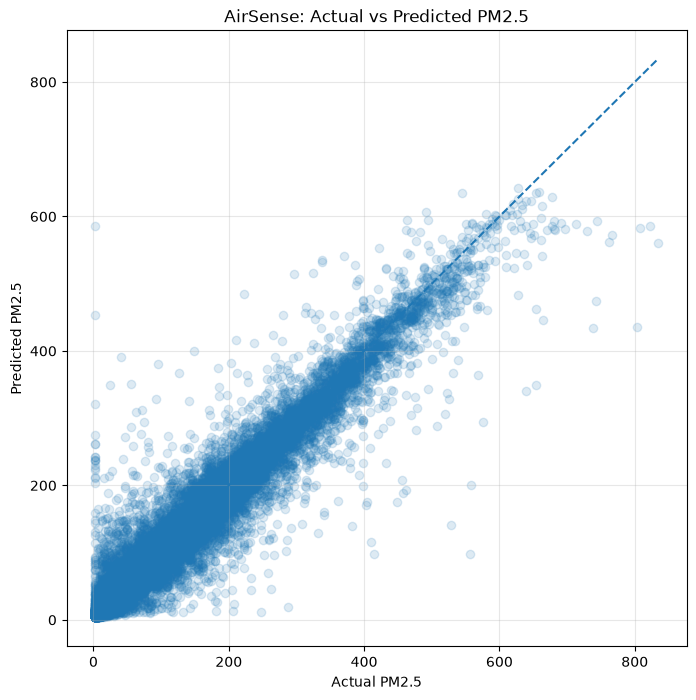

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.scatter(y_test, final_predictions, alpha=0.15)

min_value = min(y_test.min(), final_predictions.min())
max_value = max(y_test.max(), final_predictions.max())

plt.plot([min_value, max_value], [min_value, max_value],linestyle="--")
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("AirSense: Actual vs Predicted PM2.5")
plt.grid(alpha=0.3)
plt.show()

In [63]:
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(FIGURE_DIR / "actual_vs_predicted_pm25.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [64]:
import joblib
from pathlib import Path

# Define the models directory
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the fitted model pipeline
model_path = MODEL_DIR / "airsense_random_forest.joblib"

joblib.dump(final_model, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: C:\Users\HomePC\ML Zoomcamp 2026\Homework\Homework 7 Midterm Project\models\airsense_random_forest.joblib


In [65]:
loaded_model = joblib.load(model_path)

# Generate predictions using the exported model
exported_predictions = loaded_model.predict(X_test_B)

# Compare with the original predictions
import numpy as np

print(
    "Predictions identical:",
    np.allclose(final_predictions, exported_predictions)
)

print("Original predictions:", final_predictions[:5])
print("Exported predictions:", exported_predictions[:5])

Predictions identical: True
Original predictions: [41.76616672 42.34751836 51.69480754 48.67126876 50.92054467]
Exported predictions: [41.76616672 42.34751836 51.69480754 48.67126876 50.92054467]


In [66]:
# Select the first observation from the test dataset
sample = X_test_B.iloc[0]

# Generate a prediction directly from the trained model
notebook_prediction = final_model.predict(pd.DataFrame([sample]))[0]

print("Test observation:")
display(sample.to_frame(name="value"))

print(f"\nNotebook prediction: {notebook_prediction:.6f}")
print(f"Actual PM2.5: {y_test.iloc[0]:.3f}")

Test observation:


,value
PM2.5,37.0
pm25_lag_1,39.0
pm25_lag_3,45.0
pm25_lag_6,37.0
pm25_lag_24,128.0
pm25_rolling_mean_3,42.666667
pm25_rolling_mean_6,41.0
pm25_rolling_mean_24,116.75
hour,5
day_of_week,6



Notebook prediction: 41.766167
Actual PM2.5: 37.000


In [67]:
api_payload = sample.to_dict()

# Convert the feature name to the API's expected field name
api_payload["PM2_5"] = api_payload.pop("PM2.5")

api_payload

{'pm25_lag_1': 39.0,
 'pm25_lag_3': 45.0,
 'pm25_lag_6': 37.0,
 'pm25_lag_24': 128.0,
 'pm25_rolling_mean_3': 42.666666666666664,
 'pm25_rolling_mean_6': 41.0,
 'pm25_rolling_mean_24': 116.75,
 'hour': 5,
 'day_of_week': 6,
 'month': 7,
 'day_of_year': 206,
 'TEMP': 24.7,
 'PRES': 999.7,
 'DEWP': 23.5,
 'RAIN': 0.0,
 'WSPM': 0.8,
 'station': 'Aotizhongxin',
 'wd': 'E',
 'PM2_5': 37.0}